In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#Import các thư viện cần thiết
import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (classification_report, confusion_matrix,
                             precision_score, recall_score, f1_score)

In [ ]:
MODEL_DIR = '/content/drive/MyDrive/CS231.Q21/models'
IMG_SIZE = (224,224)
BATCH_SIZE = 32
EPOCHS = 10

In [ ]:
import os
os.listdir('/content/drive/MyDrive/CS231.Q21/dataset')

['fruit']

In [ ]:
#Load dataset


train_ds = tf.keras.utils.image_dataset_from_directory(
    '/content/drive/MyDrive/CS231.Q21/dataset/fruit/train',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    '/content/drive/MyDrive/CS231.Q21/dataset/fruit/val',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    seed=42
)

test_ds = keras.utils.image_dataset_from_directory(
    '/content/drive/MyDrive/CS231.Q21/dataset/fruit/test',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)
class_names = train_ds.class_names
num_classes = len(class_names)


Found 4200 files belonging to 5 classes.
Found 900 files belonging to 5 classes.
Found 900 files belonging to 5 classes.


In [ ]:
print(num_classes)
print(class_names)

5
['apple', 'banana', 'mango', 'orange', 'tomato']


In [ ]:
#Check size của 1 batch dữ liệu
for image,label in train_ds.take(1) :
    print(image.shape)
    print(label.shape)

(32, 224, 224, 3)
(32,)


In [ ]:
for images, labels in train_ds.take(1):
    for i in range(len(images)):
        img = images[i].numpy()
        label = labels[i].numpy()

        plt.imshow(img.astype("uint8"))
        plt.title(f"Label: {label}")
        plt.axis("off")
        plt.show()


Output hidden; open in https://colab.research.google.com to view.

#Xử lý trong RAM , tăng tốc độ train

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)
test_ds  = test_ds.cache().prefetch(AUTOTUNE)

# MODEL CNN BASELINE

In [ ]:
model = keras.Sequential([
    # Rescale pixel về [0, 1]
    keras.layers.Rescaling(1./255, input_shape=(*IMG_SIZE, 3)),

    # Augmentation
    keras.layers.RandomFlip('horizontal'),
    keras.layers.RandomRotation(0.083),    # 15 độ

    # Block 1 — 32 filters
    keras.layers.Conv2D(32, (3,3), activation='relu', padding='same'),
    keras.layers.BatchNormalization(),
    keras.layers.MaxPooling2D(2, 2),
    keras.layers.Dropout(0.25),

    # Block 2 — 64 filters
    keras.layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    keras.layers.BatchNormalization(),
    keras.layers.MaxPooling2D(2, 2),
    keras.layers.Dropout(0.25),

    # Block 3 — 128 filters
    keras.layers.Conv2D(128, (3,3), activation='relu', padding='same'),
    keras.layers.BatchNormalization(),
    keras.layers.MaxPooling2D(2, 2),
    keras.layers.Dropout(0.25),

    # Classifier
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(num_classes, activation='softmax')
], name='CNN_Baseline_Dropout')

model.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "CNN_Baseline_Dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,301 (434.77 KB)

 Trainable params: 110,853 (433.02 KB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
# Compile
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Sử dụng Early Stopping

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5,
        restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5,
        patience=3, verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        filepath=f'{MODEL_DIR}/best_model.keras',
        monitor='val_accuracy',
        save_best_only=True, verbose=1
    )
]

In [ ]:
# 6. TRAIN
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

# Lưu model cuối
model.save(f'{MODEL_DIR}/final_model.keras')
print(f"Model saved to {MODEL_DIR}/")


Epoch 1/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.6584 - loss: 0.9057
Epoch 1: val_accuracy improved from None to 0.31444, saving model to /content/drive/MyDrive/CS231.Q21/models/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/CS231.Q21/models/best_model.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 936s 7s/step - accuracy: 0.7531 - loss: 0.6951 - val_accuracy: 0.3144 - val_loss: 1.5060 - learning_rate: 0.0010
Epoch 2/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.8459 - loss: 0.4563
Epoch 2: val_accuracy improved from 0.31444 to 0.38667, saving model to /content/drive/MyDrive/CS231.Q21/models/best_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/CS231.Q21/models/best_model.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 769s 6s/step - accuracy: 0.8474 - loss: 0.4556 - val_accuracy: 0.3867 - val_loss: 1.2691 - learning_rate: 0.0010
Epoch 3/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8631 - loss: 0.4011
Epoch 3: val_accuracy 

In [ ]:
# 7. EVALUATE TRÊN TEST SET
y_true, y_pred = [], []
for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(labels.numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

test_loss, test_acc = model.evaluate(test_ds, verbose=0)
precision = precision_score(y_true, y_pred, average='weighted')
recall    = recall_score(y_true, y_pred, average='weighted')
f1        = f1_score(y_true, y_pred, average='weighted')

print("\n" + "="*45)
print(f"  Test Accuracy  : {test_acc:.4f}")
print(f"  Precision      : {precision:.4f}")
print(f"  Recall         : {recall:.4f}")
print(f"  F1-score       : {f1:.4f}")
print("="*45)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))


  Test Accuracy  : 0.8700
  Precision      : 0.8820
  Recall         : 0.8700
  F1-score       : 0.8658

Classification Report:
              precision    recall  f1-score   support

       apple       0.92      0.59      0.72       180
      banana       0.91      0.97      0.94       180
       mango       0.93      0.91      0.92       180
      orange       0.94      0.96      0.95       180
      tomato       0.72      0.92      0.81       180

    accuracy                           0.87       900
   macro avg       0.88      0.87      0.87       900
weighted avg       0.88      0.87      0.87       900



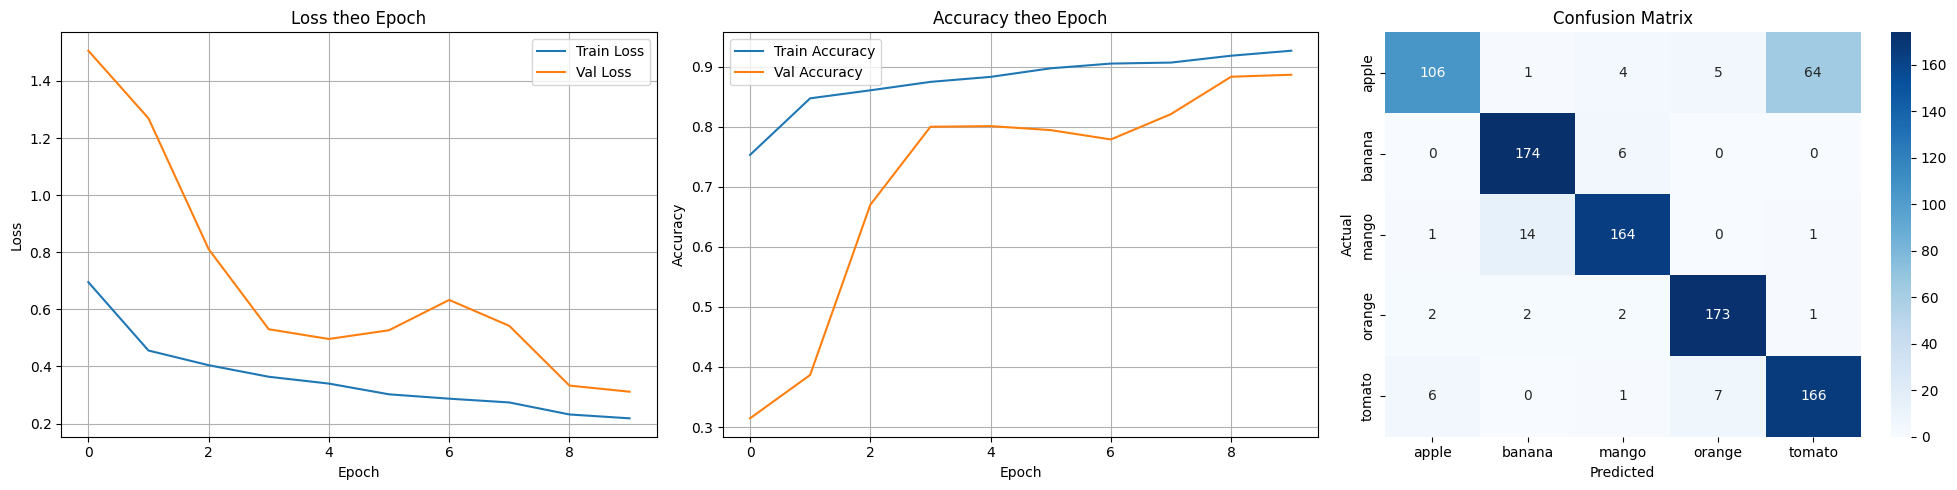

In [ ]:
# 8. VISUALIZE
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Loss curve
axes[0].plot(history.history['loss'],     label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Val Loss')
axes[0].set_title('Loss theo Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

# Accuracy curve
axes[1].plot(history.history['accuracy'],     label='Train Accuracy')
axes[1].plot(history.history['val_accuracy'], label='Val Accuracy')
axes[1].set_title('Accuracy theo Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[2])
axes[2].set_title('Confusion Matrix')
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('Actual')

plt.tight_layout()
plt.savefig(f'{MODEL_DIR}/results.png', dpi=150)
plt.show()